# ROI_processing

In [ ]:
import spatialdata_io
import spatialdata as sd
import troutpy
import scanpy as sc
from spatialdata import SpatialData
import matplotlib.pyplot as plt
from spatialdata.transformations import get_transformation
import matplotlib.patches as patches
import os
import numpy as np
import sys
import seaborn as sns

import hotspot

In [51]:
# Technology 1: Xenium
sdata = sd.read_zarr("/media/sergio/Meninges/troutpy/rois/xenium_hsskin_5k/data_processed.zarr")

# 0. Testing diffussion

In [52]:
extracellular_transcripts=sdata['extracellular_transcripts'][['x','y','z','gene','extracellular']].compute()
transcripts=sdata['transcripts'][['x','y','z','gene','extracellular']].compute()
transcripts=transcripts[transcripts['extracellular']==False]

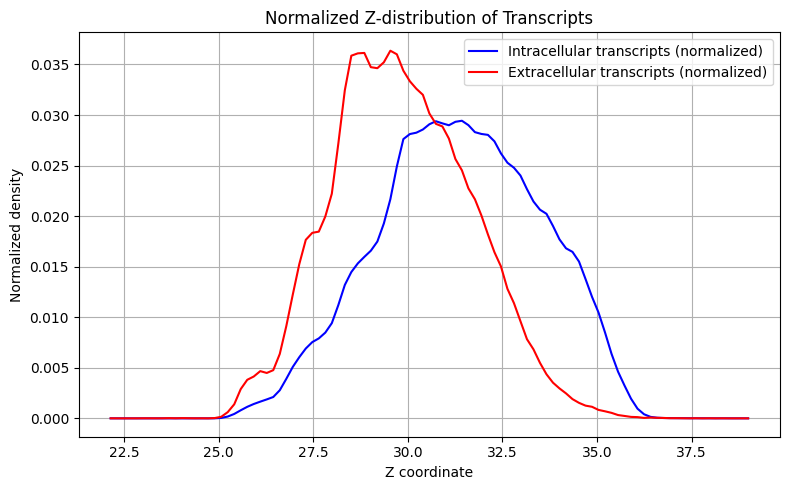

In [57]:
import numpy as np
import matplotlib.pyplot as plt

# Compute histograms
bins = np.linspace(min(transcripts['z'].min(), extracellular_transcripts['z'].min()),
                   max(transcripts['z'].max(), extracellular_transcripts['z'].max()), 100)

hist_all, _ = np.histogram(transcripts['z'], bins=bins)
hist_extra, _ = np.histogram(extracellular_transcripts['z'], bins=bins)

# Normalize
hist_all = hist_all / hist_all.sum()
hist_extra = hist_extra / hist_extra.sum()

# Compute bin centers for plotting
bin_centers = (bins[:-1] + bins[1:]) / 2

# Plot
plt.figure(figsize=(8, 5))
plt.plot(bin_centers, hist_all, label='Intracellular transcripts (normalized)', color='blue')
plt.plot(bin_centers, hist_extra, label='Extracellular transcripts (normalized)', color='red')
plt.xlabel('Z coordinate')
plt.ylabel('Normalized density')
plt.title('Normalized Z-distribution of Transcripts')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [54]:
import numpy as np
import pandas as pd
from scipy.stats import zscore

# Define number of spatial bins
n_bins = 40

# Assign spatial bins
transcripts['x_bin'] = pd.qcut(transcripts['x'], q=n_bins, duplicates='drop')
transcripts['y_bin'] = pd.qcut(transcripts['y'], q=n_bins, duplicates='drop')

# Compute local mean and std for z
local_stats = transcripts.groupby(['x_bin', 'y_bin'])['z'].agg(['mean', 'std']).reset_index()
transcripts = transcripts.merge(local_stats, on=['x_bin', 'y_bin'], how='left')

# Local z-score
transcripts['z_local'] = (transcripts['z'] - transcripts['mean']) / transcripts['std']

# Define number of spatial bins
n_bins = 40

# Assign spatial bins
extracellular_transcripts['x_bin'] = pd.qcut(extracellular_transcripts['x'], q=n_bins, duplicates='drop')
extracellular_transcripts['y_bin'] = pd.qcut(extracellular_transcripts['y'], q=n_bins, duplicates='drop')

# Compute local mean and std for z
local_stats = extracellular_transcripts.groupby(['x_bin', 'y_bin'])['z'].agg(['mean', 'std']).reset_index()
extracellular_transcripts = extracellular_transcripts.merge(local_stats, on=['x_bin', 'y_bin'], how='left')

# Local z-score
extracellular_transcripts['z_local'] = (extracellular_transcripts['z'] - extracellular_transcripts['mean']) / extracellular_transcripts['std']


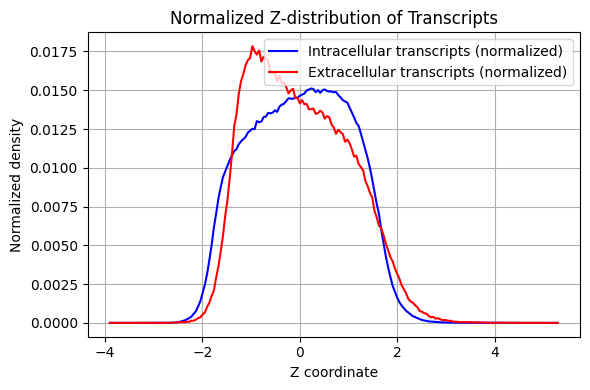

In [55]:
import numpy as np
import matplotlib.pyplot as plt

# Compute histograms
bins = np.linspace(min(transcripts['z_local'].min(), extracellular_transcripts['z_local'].min()),
                   max(transcripts['z_local'].max(), extracellular_transcripts['z_local'].max()), 200)

hist_all, _ = np.histogram(transcripts['z_local'], bins=bins)
hist_extra, _ = np.histogram(extracellular_transcripts['z_local'], bins=bins)

# Normalize
hist_all = hist_all / hist_all.sum()
hist_extra = hist_extra / hist_extra.sum()

# Compute bin centers for plotting
bin_centers = (bins[:-1] + bins[1:]) / 2

# Plot
plt.figure(figsize=(6, 4))
plt.plot(bin_centers, hist_all, label='Intracellular transcripts (normalized)', color='blue')
plt.plot(bin_centers, hist_extra, label='Extracellular transcripts (normalized)', color='red')
plt.xlabel('Z coordinate')
plt.ylabel('Normalized density')
plt.title('Normalized Z-distribution of Transcripts')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


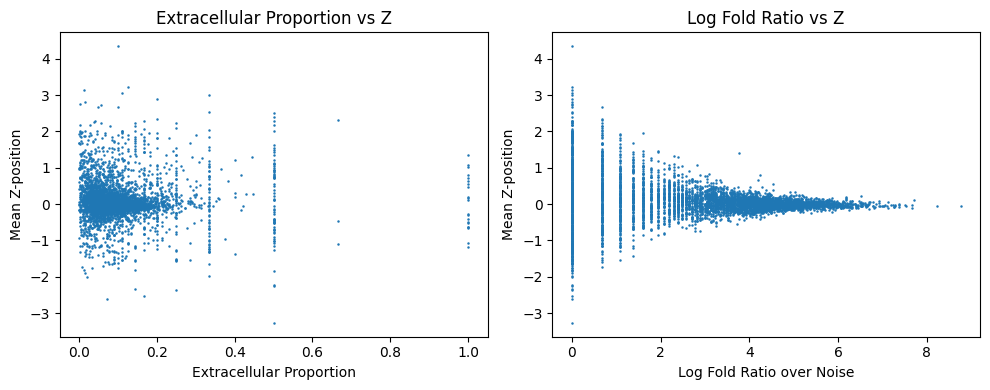

In [56]:
z_norm=extracellular_transcripts.loc[:,['z_local','gene']].groupby('gene').mean().sort_values(by='z_local')
z_norm=z_norm[~z_norm['z_local'].isna()]
extracellular_proportion=sdata['xrna_metadata'].var.loc[:,['extracellular_proportion','logfoldratio_over_noise']]
merged = extracellular_proportion.merge(z_norm, left_index=True, right_index=True)

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 4))  # 1 row, 2 columns

# First subplot
axes[0].scatter(merged['extracellular_proportion'], merged['z_local'], s=0.6)
axes[0].set_xlabel('Extracellular Proportion')
axes[0].set_ylabel('Mean Z-position')
axes[0].set_title('Extracellular Proportion vs Z')

# Second subplot
axes[1].scatter(merged['logfoldratio_over_noise'], merged['z_local'], s=0.6)
axes[1].set_xlabel('Log Fold Ratio over Noise')
axes[1].set_ylabel('Mean Z-position')
axes[1].set_title('Log Fold Ratio vs Z')

plt.tight_layout()
plt.show()


In [ ]:
np.mean(transcripts['z_local'])

3.9751558e-09

In [27]:
np.mean(extracellular_transcripts['z_local'])

-1.4604125e-09

# 1. Additional unimodal plots

In [ ]:
from matplotlib.colors import ListedColormap, Normalize
import matplotlib.pyplot as plt
import geopandas as gpd
from shapely.affinity import affine_transform
from shapely.geometry import box
import numpy as np
import pandas as pd


def spatial_transcripts(
    sdata: SpatialData,
    gene_key: str = "gene",
    gene_list: list[str] | None = None,
    color_key: str = "transcript_type",
    shapes_key: str = "cell_boundaries",
    colormap: str = "30colors",
    boundary_linewidth: float = 0.5,
    scatter_size: float = 1.0,
    alpha: float = 0.8,
    use_roi: bool = False,
    roi: tuple[float, float, float, float] = (0, 20000, 0, 20000),
    figsize: tuple[float, float] = (8, 8),
    title: str = "Cell Boundaries + Transcripts",
) -> tuple[plt.Figure, plt.Axes]:
    """
    Plot cell boundary polygons and transcript points, colored by a categorical variable
    or a numeric variable, scaling geometries by an affine matrix from get_transformation.

    Parameters
    ----------
    sdata
        A SpatialData object containing:
          - sdata[shapes_key]  including a 'geometry' column of shapely Polygons
          - sdata['transcripts'] including `gene_key` and `color_key`
    gene_key: str
        Column in transcripts to filter by gene_list.
    gene_list: Optional[List[str]]
        List of genes to keep. If None, all transcripts are used.
    color_key: str
        Column in transcripts used for coloring points. Can be categorical or numeric.
    shapes_key: str
        Key in sdata for your polygon boundaries layer.
    colormap: str
        Name of a Matplotlib colormap or troutpy palette name.
    boundary_linewidth: float
        Line width of cell boundary outlines.
    scatter_size: float
        Marker size for transcript points.
    alpha: float
        Transparency for transcript points.
    use_roi: bool
        If True, restrict both polygons and points to the bounding box given by `roi`.
    roi: Tuple[float, float, float, float]
        (xmin, xmax, ymin, ymax) bounds to clip to when `use_roi=True`.
    figsize: Tuple[float, float]
        Width and height of the figure.
    title: str
        Title string placed above the plot.

    Returns
    -------
    fig, ax
        The Matplotlib figure and axes objects.
    """
    # 1) Filter transcripts by gene_list
    trans_ad = sdata["transcripts"].compute()
    if gene_list is not None:
        trans_ad = trans_ad[trans_ad[gene_key].isin(gene_list)]

    # annotate transcript types
    trans_ad["segstatus"] = trans_ad["overlaps_cell"].astype(str) + "_" + trans_ad["extracellular"].astype(str)
    stat2lab = {"True_False": "cell", "False_True": "extracellular", "False_False": "cell-like"}
    trans_ad["transcript_type"] = trans_ad["segstatus"].map(stat2lab)

    # 2) Prepare color values based on type (categorical or numeric)
    trans_df = trans_ad.copy()
    if pd.api.types.is_numeric_dtype(trans_df[color_key]):
        is_numeric = True
        color_values = trans_df[color_key].astype(float)
        cmap = plt.get_cmap(colormap)
        norm = Normalize(vmin=color_values.min(), vmax=color_values.max())
    else:
        is_numeric = False
        cats = trans_df[color_key].astype("category")
        color_values = cats.cat.codes.values
        n_cats = len(cats.cat.categories)
        try:
            import troutpy
            pal = troutpy.pl.get_palette(colormap, n_cats)
            cmap = ListedColormap(pal)
        except Exception:
            cmap = plt.get_cmap(colormap, n_cats)

    # 3) Obtain affine transformation and apply to geometries and points
    cb = sdata[shapes_key]
    df = cb.copy()
    trans = get_transformation(cb)
    
    if hasattr(trans, "matrix") and trans.matrix is not None:
        try:
            matrix = trans.matrix  # expected 3x3 or 2x3 affine
            a, b, xoff = matrix[0]
            d, e, yoff = matrix[1]
            params = [a, b, d, e, xoff, yoff]
            df["geometry"] = df["geometry"].apply(lambda geom: affine_transform(geom, params))
        except Exception as e:
            print(f"Transformation could not be applied: {e}")
    else:
        print("No transformation matrix found. Proceeding without transformation.")

    gdf = gpd.GeoDataFrame(df, geometry="geometry", crs=None)

    # 4) Optionally clip to ROI
    if use_roi:
        xmin, xmax, ymin, ymax = roi
        roi_poly = box(xmin, ymin, xmax, ymax)
        gdf = gdf[gdf.geometry.intersects(roi_poly)]
        mask = (trans_df["x"] >= xmin) & (trans_df["x"] <= xmax) & (trans_df["y"] >= ymin) & (trans_df["y"] <= ymax)
        trans_df = trans_df[mask]
        color_values = color_values[mask]  # mask color values too

    # 5) Plot
    fig, ax = plt.subplots(figsize=figsize)
    gdf.plot(ax=ax, facecolor="none", edgecolor="black", linewidth=boundary_linewidth)
    scatter = ax.scatter(
        trans_df["x"],
        trans_df["y"],
        c=color_values,
        cmap=cmap,
        s=scatter_size,
        edgecolor="none",
        alpha=alpha,
        norm=norm if is_numeric else None,
    )

    # 6) Legend or colorbar
    if is_numeric:
        cbar = fig.colorbar(scatter, ax=ax, label=color_key, fraction=0.046, pad=0.04)
    else:
        for idx, cat in enumerate(cats.cat.categories):
            ax.scatter([], [], color=cmap(idx), label=str(cat), s=20)
        ax.legend(title=color_key, markerscale=1.5, bbox_to_anchor=(1.02, 1), loc="upper left")

    ax.set_aspect("equal")
    ax.set_title(title)
    if use_roi:
        ax.set_xlim(roi[0], roi[1])
        ax.set_ylim(roi[2], roi[3])
    ax.axis("off")
    plt.tight_layout()

    return fig, ax


In [ ]:
sdata

In [ ]:
spatial_transcripts(sdata, color_key="overlaps_cell", colormap="viridis",shapes_key='cell_boundaries',scatter_size=0.07,figsize=(10,10),boundary_linewidth=0.1)


In [ ]:
spatial_transcripts(sdata,shapes_key='cell_boundaries',scatter_size=0.07,figsize=(10,10),boundary_linewidth=0.1)


In [ ]:
troutpy.pl.metric_scatter(
    sdata,
    x="logfoldratio_over_noise",
    y="extracellular_proportion",
    label_top_n_y=10,
    label_bottom_n_y=0,
    label_top_n_x=5
)

In [ ]:
troutpy.pl.diffusion_results(sdata, y_col="-log_ks_pval", y_logscale=True,x_col='extracellular_proportion',label_top_n_x=5)

In [ ]:
sdata['transcripts']

# 2. Multivariate analysis

In [ ]:
adata = sdata.tables["segmentation_free_table"]
adata.raw = adata
sc.pp.filter_genes(adata, min_cells=2)
sc.pp.filter_cells(adata, min_genes=3)
sc.pp.filter_cells(adata, min_counts=10)

adata.layers["raw"] = adata.X.copy()
sc.pp.normalize_total(adata)
# Logarithmize the data
sc.pp.log1p(adata)
# pca
sc.tl.pca(adata)
# neighbors
sc.pp.neighbors(adata, n_neighbors=30)
sc.tl.umap(adata)
sc.tl.leiden(adata, key_added="leiden", resolution=0.7)
sc.tl.rank_genes_groups(adata, "leiden", method="t-test", n_genes=10)

In [ ]:
sc.pl.umap(adata, color="leiden", palette="Accent", s=100)
# plot 
fig, ax = plt.subplots(figsize=(7, 7))
sc.pl.spatial(adata, color="leiden", spot_size=20, show=False, ax=ax, marker="s")
# fig,ax=plt.subplots(figsize=(7,7))
sc.pl.spatial(sdata["table"],color="leiden",spot_size=7,show=False, ax=ax,add_outline=True,outline_width=(0.5, 0))
sc.pl.rank_genes_groups_dotplot(adata, groupby="leiden", n_genes=8)

In [ ]:
sc.pl.umap(sdata["table"],color="leiden")
sc.pl.spatial(sdata["table"],color="leiden",spot_size=6,add_outline=False,outline_width=(0.5, 0))
sc.pl.rank_genes_groups_dotplot(sdata['table'],groupby='leiden',n_genes=10)

In [ ]:
troutpy.pl.spatial_transcripts(sdata,shapes_key='shapes',scatter_size=0.07,figsize=(10,10),boundary_linewidth=0.3)
troutpy.pl.spatial_transcripts(sdata,gene_list=['KRT1'],shapes_key='shapes',scatter_size=1.5,figsize=(10,10),boundary_linewidth=0.3,title='KRT1')
troutpy.pl.spatial_transcripts(sdata,gene_list=['FABP5'],shapes_key='shapes',scatter_size=1.5,figsize=(10,10),boundary_linewidth=0.3,title='FABP5')

In [ ]:
troutpy.pl.spatial_transcripts(sdata,shapes_key='shapes',color_key='closest_cell_type',scatter_size=0.07,figsize=(10,10),boundary_linewidth=0.3)

In [ ]:
troutpy.pl.source_score_by_celltype(sdata, figsize=(4, 6))

In [ ]:
troutpy.tl.cluster_distribution_from_source(sdata, n_clusters=4)

In [ ]:
troutpy.pl.global_distribution_from_source(sdata, cluster_key="kmeans_distribution", distance_key="distance", n_bins=40, how="collapsed")


In [ ]:
troutpy.pl.distributions_by_cluster(sdata, groups=[1])

In [ ]:
troutpy.pl.gene_distribution_from_source(sdata, ['KRT1'])

## Target-score

In [ ]:
troutpy.tl.compute_target_score(sdata,layer="transcripts",lambda_decay=0.1,copy=False,celltype_key="leiden",gene_key='gene')

In [ ]:
troutpy.pl.target_score_by_celltype(sdata, figsize=(5, 5),gene_key='gene')

## Communication strenght

In [ ]:
troutpy.tl.compute_communication_strength(sdata)

In [ ]:
troutpy.tl.gene_specific_interactions(sdata, copy=False)

In [ ]:
troutpy.pl.celltype_communication(sdata, kind="heatmap", celltype_key="cell type", figsize=(6, 6))

## Latent factor analysis

In [ ]:
troutpy.tl.latent_factor(sdata, method="NMF", layer="segmentation_free_table", n_components=10)

In [ ]:
troutpy.tl.apply_exrna_factors_to_cells(sdata, extracellular_layer="segmentation_free_table", cellular_layer="table")

In [ ]:
troutpy.pl.rank_factor_genes_loadings_matrixplot(sdata, layer="segmentation_free_table", n_genes=1, cmap="troutpy_reversed")

In [ ]:
troutpy.pl.rank_factor_genes_loadings(sdata, layer="segmentation_free_table", n_genes=10)

In [ ]:
troutpy.pl.factors_in_cells(sdata, layer="table", cmap="troutpy", method="heatmap",celltype_key='leiden')

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import scanpy as sc

import troutpy as tp


def plot_factor_loadings(sdata, layer_cells="table", layer_extra="segmentation_free_table", spot_size_cells=7, spot_size_extra=12):
    """
    Plots factor loadings for each factor in a single figure with subplots,showing both intra- and extra-cellular scores.

    Parameters
    ----------
    sdata
        SpatialData object containing cell and extra-cellular data.

    layer_cells
        Key in sdata where *cell* factor loadings are stored.

    layer_extra
        Key in sdata where *extra-cellular* factor loadings are stored.

    spot_size_cells
        Size of the marker for cells.

    spot_size_extra
        Size of the marker for extra-cellular spots.
    """
    cell_loadings = sc.AnnData(sdata[layer_cells].obsm["factors_cell_loadings"], obs=sdata[layer_cells].obs)
    cell_loadings.var.index = [f"Factor {i + 1}" for i in range(cell_loadings.shape[1])]
    cell_loadings.obsm["spatial"] = sdata[layer_cells].obsm["spatial"]

    extra_loadings = sc.AnnData(sdata[layer_extra].obsm["cell_loadings"], obs=sdata[layer_extra].obs)
    extra_loadings.var.index = [f"Factor {i + 1}" for i in range(extra_loadings.shape[1])]
    extra_loadings.obsm["spatial"] = sdata[layer_extra].obsm["spatial"]

    n_factors = cell_loadings.shape[1]

    cold_palette = tp.pl.get_colormap("Aquas")  # For intra-cellular factors
    warm_palette = tp.pl.get_colormap("Pinks")  # For extra-cellular factors

    n_cols = 2  # Number of columns in the grid
    n_rows = int(np.ceil(n_factors / n_cols))  # Compute number of rows needed
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(10 * n_cols, 10 * n_rows))
    axes = axes.flatten()  # Flatten in case of single row

    for i in range(n_factors):
        ax = axes[i]
        factor_name = f"Factor {i + 1}"

        # Plot extra-cellular loadings (background)
        sc.pl.spatial(
            extra_loadings, color=factor_name, spot_size=spot_size_extra, show=False, ax=ax, cmap=warm_palette, marker="*", colorbar_loc=None
        )

        # Plot intra-cellular loadings (foreground with black outline)
        sc.pl.spatial(
            cell_loadings,
            color=factor_name,
            spot_size=spot_size_cells,
            show=False,
            ax=ax,
            cmap=cold_palette,
            edgecolor="black",
            linewidth=0.5,
            colorbar_loc=None,
        )

        ax.set_title(factor_name)

    # Remove empty subplots if n_factors is not a multiple of n_cols
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

In [ ]:
plot_factor_loadings(sdata, layer_cells="table", layer_extra="segmentation_free_table", spot_size_cells=5)

In [ ]:
troutpy.pl.spatial_transcripts(sdata,gene_list=['KRT1'],shapes_key='shapes',scatter_size=1.5,figsize=(10,10),boundary_linewidth=0.3,title='KRT1')
troutpy.pl.spatial_transcripts(sdata,gene_list=['KRT14'],shapes_key='shapes',scatter_size=1.5,figsize=(10,10),boundary_linewidth=0.3,title='KRT14')

In [ ]:
troutpy.pl.spatial_transcripts(sdata,gene_list=['FABP5'],shapes_key='shapes',scatter_size=1.5,figsize=(10,10),boundary_linewidth=0.3,title='FABP5')

## Multimodal analysis

In [ ]:
sdata

### This is currently not working, to be fixed

In [ ]:
image_intensities_per_transcript(
sdata, image_key="morphology_focus", scale="scale0", transcript_key="transcripts", extracellular=True, copy=False,
)

In [ ]:
get_transformation(sdata['morphology_focus'])

In [ ]:
ad = sdata["image_intensity_per_transcript"]
sc.pl.spatial(ad, color=ad.var.index, spot_size=10, cmap="YlGnBu", vmax="p99", ncols=4,scale)

# Module analysis

In [ ]:
adata = sdata["table"]
hs = hotspot.Hotspot(adata, layer_key="raw", model="danb", latent_obsm_key="X_pca", umi_counts_obs_key="n_counts")

hs.create_knn_graph(weighted_graph=False, n_neighbors=10)
hs_results = hs.compute_autocorrelations()
hs_genes = hs_results.loc[hs_results.FDR < 0.005].index  # Select genes
local_correlations = hs.compute_local_correlations(hs_genes, jobs=4)  # jobs for parallelization

In [ ]:
# calculate modules
modules = hs.create_modules(min_gene_threshold=10, core_only=True, fdr_threshold=0.0005)
module_scores = hs.calculate_module_scores()

In [ ]:
hs.plot_local_correlations(vmax=10, vmin=-10)

In [ ]:
adata_scores = sc.AnnData(module_scores, obs=adata.obs)
adata_scores.obsm["X_umap"] = adata.obsm["X_umap"]
adata_scores.obsm["X_pca"] = adata.obsm["X_pca"]
sc.pl.umap(adata, color="leiden")
sc.pl.umap(adata_scores, color=adata_scores.var.index, vmax="p99")

In [ ]:
dictmod = dict(zip(modules.index, modules.values))
results=sdata['xrna_metadata'].var
results["module"] = results.index.map(dictmod)

In [ ]:
import matplotlib.pyplot as plt


def annotate_top_bottom(
    df, metric1, metric2, n=5, label_col=None, figsize=(8, 6), scatter_kwargs=None, annotate_kwargs=None, title_tag=""
):
    """
    Scatter-plot df[metric1] vs df[metric2] and annotate the top/bottom n points
    along each axis.

    Parameters
    ----------
    df : pandas.DataFrame
        The data.
    metric1 : str
        Column name for the x-axis metric.
    metric2 : str
        Column name for the y-axis metric.
    n : int, optional (default=5)
        Number of top and bottom points to label per metric.
    label_col : str or None, optional (default=None)
        Column name containing the labels. If None, uses df.index.
    figsize : tuple, optional (default=(8, 6))
        Figure size.
    scatter_kwargs : dict or None
        Extra kwargs passed to plt.scatter().
    annotate_kwargs : dict or None
        Extra kwargs passed to plt.annotate().
    Title tag: str, optional (default='')

    Returns
    -------
    fig, ax : matplotlib.figure.Figure, matplotlib.axes.Axes
        The figure and axes objects.
    """
    # Prepare labels
    df_plot = df.copy()
    if label_col is None:
        df_plot["__idx_label"] = df_plot.index.astype(str)
        label_col = "__idx_label"

    # Plot
    fig, ax = plt.subplots(figsize=figsize)
    sc_kwargs = {} if scatter_kwargs is None else scatter_kwargs
    ax.scatter(df_plot[metric1], df_plot[metric2], **sc_kwargs)
    ax.set_xlabel(metric1)
    ax.set_ylabel(metric2)
    ax.set_title(f"{title_tag}: {metric1} vs {metric2}")

    # Find indices to annotate
    top1 = df_plot.nlargest(n, metric1).index
    bot1 = df_plot.nsmallest(n, metric1).index
    top2 = df_plot.nlargest(n, metric2).index
    bot2 = df_plot.nsmallest(n, metric2).index
    to_annotate = set(top1) | set(bot1) | set(top2) | set(bot2)

    # Annotate
    ann_kwargs = dict(xytext=(5, 5), textcoords="offset points", ha="left", va="bottom", fontsize=8, alpha=0.8)
    if annotate_kwargs:
        ann_kwargs.update(annotate_kwargs)

    for idx in to_annotate:
        x = df_plot.loc[idx, metric1]
        y = df_plot.loc[idx, metric2]
        label = df_plot.loc[idx, label_col]
        ax.annotate(label, xy=(x, y), **ann_kwargs)

    fig.tight_layout()
    return fig, ax

In [ ]:
results2 = results[results["logfoldratio_over_noise"] > 0]
fig, ax = annotate_top_bottom(
    df=results2,
    metric1="logfoldratio_over_noise",
    metric2="in_out_spearmanR",
    n=10,
    scatter_kwargs={"alpha": 0.6, "s": 30},
    annotate_kwargs={"fontsize": 9, "color": "black"},
    figsize=(7, 7),
)
plt.show()

In [ ]:
fig, ax = annotate_top_bottom(
    df=results2,
    metric1="logfoldratio_over_noise",
    metric2="extracellular_proportion",
    n=50,
    scatter_kwargs={"alpha": 0.6, "s": 30},
    annotate_kwargs={"fontsize": 9, "color": "black"},
    figsize=(7, 7),
)
plt.show()

In [ ]:
# spatial maps-in out
g2 = "Gap43"
troutpy.pl.spatial_inout_expression(sdata, g2, spot_size_cells=10)

In [ ]:
for g, i in results.groupby("module"):
    if g > -1:
        print(g)
        # Suppose `results` is your DataFrame and you have a column 'gene' with names:
        fig, ax = annotate_top_bottom(
            df=i,
            metric1="logfoldratio_over_noise",
            metric2="extracellular_proportion",
            n=5,
            scatter_kwargs={"alpha": 0.6, "s": 30},
            annotate_kwargs={"fontsize": 9, "color": "black"},
            title_tag=g,
            figsize=(4, 4),
        )
        plt.show()

In [ ]:
for g, i in results.groupby("module"):
    if g > -1:
        print(g)
        # Suppose `results` is your DataFrame and you have a column 'gene' with names:
        fig, ax = annotate_top_bottom(
            df=i,
            metric1="logfoldratio_over_noise",
            metric2="in_out_spearmanR",
            n=5,
            scatter_kwargs={"alpha": 0.6, "s": 30},
            annotate_kwargs={"fontsize": 9, "color": "black"},
            title_tag=g,
            figsize=(4, 4),
        )
        plt.show()

In [ ]:
import pandas as pd

mods_df = pd.DataFrame(modules).sort_values(by="Module")
genes = mods_df[mods_df["Module"] == 1].index
sc.pl.umap(adata, color=genes, vmax="p99")
print(genes)

In [ ]:
g2 = "CAVIN2"
troutpy.pl.spatial_inout_expression(sdata, g2, spot_size_cells=40, spot_size_extra=40)

In [ ]:
g2 = "FABP4"
troutpy.pl.spatial_inout_expression(sdata, g2, spot_size_cells=40, spot_size_extra=40)

In [ ]:
merged_info.sort_values(by=[metric + "_cosmx"], ascending=False)

In [ ]:
fig, ax = annotate_top_bottom(
    df=results,
    metric1="logfoldratio_over_noise",
    metric2="extracellular_proportion",
    n=5,
    scatter_kwargs={"alpha": 0.6, "s": 30},
    annotate_kwargs={"fontsize": 9, "color": "black"},
    title_tag=g,
    figsize=(4, 4),
)
plt.show()

In [ ]:
g2 = "FZD4"
troutpy.pl.spatial_inout_expression(sdata, g2, spot_size_cells=10, spot_size_extra=10)

In [ ]:
trans = sdata["transcripts"].compute()

In [ ]:
trans["segstatus"] = trans["overlaps_cell"].astype(str) + "_" + trans["extracellular"].astype(str)
stat2lab = {"True_False": "cell", "False_True": "extracellular", "False_False": "cell-like"}

In [ ]:
trans["type"] = trans["segstatus"].map(stat2lab)

In [ ]:
trans2 = trans.loc[:, ["x", "y", "gene", "type"]]

In [ ]:
trans2.to_csv("/media/sergio/Meninges/trans2.csv")